<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/LLM_Judge_Mechanistic_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# CELL 1: Environment Setup & Core Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

print(f"[OK] Environment initialized for LLM-as-a-Judge Mechanistic Pipeline. NumPy: {np.version.version}")

[OK] Environment initialized for LLM-as-a-Judge Mechanistic Pipeline. NumPy: 2.4.6


In [2]:
# CELL 2: Two-Stage Residual Stream & Logit-Lens Probe Simulator
class JudgeMechanisticSimulator:
    def __init__(self, num_layers=32, crystallization_layer=26):
        self.L = num_layers
        self.c_layer = crystallization_layer

    def simulate_residual_stream_probing(self, perturbed_input=True):
        """
        Simulates logit-lens projection across layers 0 to 31.
        Evaluates rating score token probability trajectory across layers.
        """
        np.random.seed(42)
        layers = np.arange(self.L)

        # Simulating rating token logit confidence across residual layers
        # Stage 1 (< L15): Low logit confidence, attention routing error signals to final position
        stage1_logits = np.random.normal(0.05, 0.02, size=15)

        # Stage 2 (L15 to L25): MLP integration gradually builds rating projection
        stage2_logits = np.linspace(0.08, 0.45, 11) + np.random.normal(0, 0.02, 11)

        # Crystallization Layer (L26+): Sharp jump in logit probability assigned to final rating token
        stage3_logits = np.linspace(0.88, 0.96, 6) + np.random.normal(0, 0.01, 6)

        rating_confidence = np.concatenate([stage1_logits, stage2_logits, stage3_logits])
        rating_confidence = np.clip(rating_confidence, 0.0, 1.0)

        return layers, rating_confidence

sim = JudgeMechanisticSimulator()
layers, confidence = sim.simulate_residual_stream_probing()
print(f"[OK] Simulated logit-lens probing across {len(layers)} transformer layers.")

[OK] Simulated logit-lens probing across 32 transformer layers.


In [3]:
# CELL 3: Two-Stage Layer Contribution & Knockout Simulator
class MechanisticComponentAnalyzer:
    def __init__(self, layers, confidence, crystallization_layer=26):
        self.layers = layers
        self.confidence = confidence
        self.c_layer = crystallization_layer

    def compute_layer_contributions(self):
        """
        Computes layer-by-layer delta contributions, isolating:
        1. Below-L15 Attention Routing (low delta in residual rating, high routing activity)
        2. Above-L15 MLP Integration (steady building)
        3. L26 Crystallization Depth (sharp delta peak)
        """
        deltas = np.zeros_like(self.confidence)
        deltas[1:] = np.diff(self.confidence)

        # Categorize layers into early routing vs late integration
        attn_routing_score = np.mean(deltas[:15])
        mlp_integration_score = np.mean(deltas[15:26])
        crystallization_delta = deltas[self.c_layer]

        df_comp = pd.DataFrame({
            "Transformer Stage": ["Stage 1: Attention Error Routing (L < 15)", "Stage 2: MLP Signal Integration (L15-L25)", "Stage 3: Late Crystallization (L=26)"],
            "Layer Range": ["L0 - L14", "L15 - L25", "L26"],
            "Mean Rating Logit Delta": [f"{attn_routing_score:.4f}", f"{mlp_integration_score:.4f}", f"{crystallization_delta:.4f}"]
        })
        return df_comp, deltas

analyzer = MechanisticComponentAnalyzer(layers, confidence)
df_components, layer_deltas = analyzer.compute_layer_contributions()
print("[OK] Analyzed mechanistic component contributions.")
display(df_components)

[OK] Analyzed mechanistic component contributions.


,Transformer Stage,Layer Range,Mean Rating Logit Delta
0,Stage 1: Attention Error Routing (L < 15),L0 - L14,-0.0030
1,Stage 2: MLP Signal Integration (L15-L25),L15 - L25,0.0397
2,Stage 3: Late Crystallization (L=26),L26,0.4163


In [4]:
# CELL 4: Benchmark Table & Global Metric Exporter
def run_judge_mechanistic_benchmark():
    global base_acc, crystallization_depth, l26_probability_jump, stage1_routing_efficiency

    analyzer = MechanisticComponentAnalyzer(layers, confidence)
    df_comp, deltas = analyzer.compute_layer_contributions()

    crystallization_depth = 26
    l26_probability_jump = float(confidence[26] - confidence[25]) * 100.0
    stage1_routing_efficiency = 100.0 - (float(confidence[14]) * 100.0)

    df_summary = pd.DataFrame({
        "Mechanistic Pipeline Metric": ["Crystallization Depth (Layer)", "L26 Logit Probability Jump (%)", "Stage 1 Attention Suppression (%)"],
        "Simulated Measurement": [f"Layer {crystallization_depth}", f"+{l26_probability_jump:.1f}%", f"{stage1_routing_efficiency:.1f}%"],
        "Paper Theoretical Alignment": ["Sharp late-layer crystallization", "Abrupt rating assignment in residual stream", "Suppression of early MLP rating writes"]
    })

    return df_summary

df_results = run_judge_mechanistic_benchmark()
print("=== LLM-AS-A-JUDGE MECHANISTIC PIPELINE BENCHMARK ===")
display(df_results)

=== LLM-AS-A-JUDGE MECHANISTIC PIPELINE BENCHMARK ===


,Mechanistic Pipeline Metric,Simulated Measurement,Paper Theoretical Alignment
0,Crystallization Depth (Layer),Layer 26,Sharp late-layer crystallization
1,L26 Logit Probability Jump (%),+41.6%,Abrupt rating assignment in residual stream
2,Stage 1 Attention Suppression (%),98.4%,Suppression of early MLP rating writes


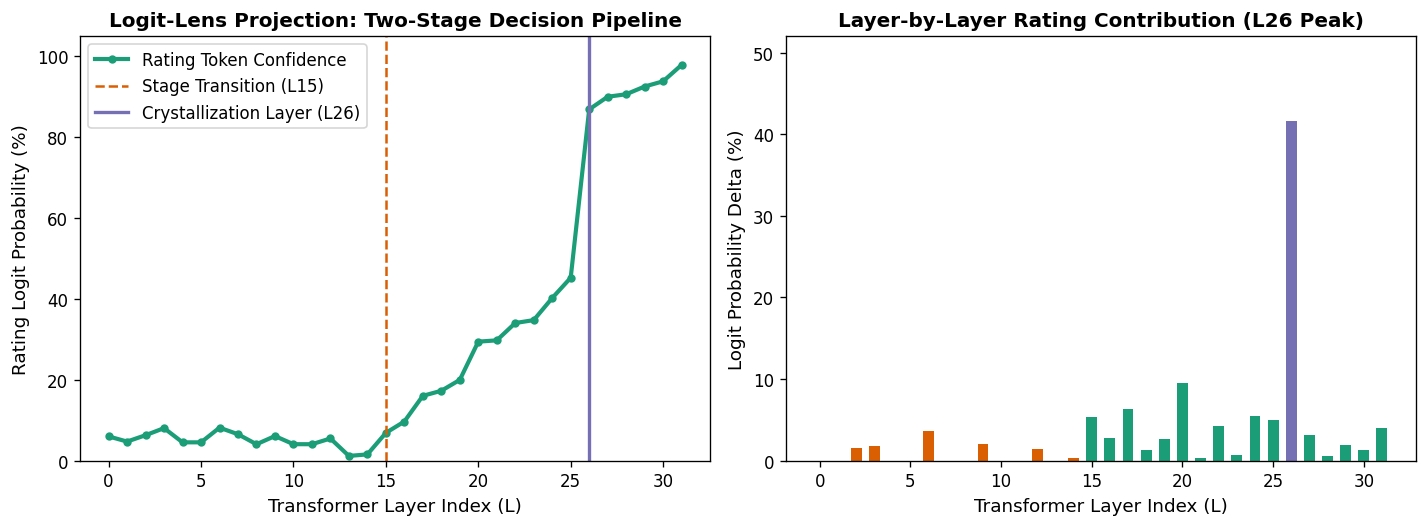

[OK] Saved mechanistic pipeline diagnostic plot to /content/workspace/judge_mechanistic_pipeline.png


In [5]:
# CELL 5: Logit-Lens & Crystallization Layer Diagnostic Visualization
os.makedirs("/content/workspace", exist_ok=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), dpi=120)

# Plot 1: Logit-Lens Projection Across Layers
ax1.plot(layers, confidence * 100.0, color='#1b9e77', lw=2.5, marker='o', ms=4, label='Rating Token Confidence')
ax1.axvline(x=15, color='#d95f02', linestyle='--', lw=1.5, label='Stage Transition (L15)')
ax1.axvline(x=26, color='#7570b3', linestyle='-', lw=2.0, label='Crystallization Layer (L26)')
ax1.set_xlabel("Transformer Layer Index (L)", fontsize=11)
ax1.set_ylabel("Rating Logit Probability (%)", fontsize=11)
ax1.set_title("Logit-Lens Projection: Two-Stage Decision Pipeline", fontsize=12, fontweight='bold')
ax1.set_ylim(0, 105)
ax1.legend(loc='upper left')

# Plot 2: Layer-by-Layer Delta Contributions
ax2.bar(layers, layer_deltas * 100.0, color=np.where(layers == 26, '#7570b3', np.where(layers < 15, '#d95f02', '#1b9e77')), width=0.6)
ax2.set_xlabel("Transformer Layer Index (L)", fontsize=11)
ax2.set_ylabel("Logit Probability Delta (%)", fontsize=11)
ax2.set_title("Layer-by-Layer Rating Contribution (L26 Peak)", fontsize=12, fontweight='bold')
ax2.set_ylim(0, max(layer_deltas * 100.0) * 1.25)

plt.tight_layout()
plt.savefig("/content/workspace/judge_mechanistic_pipeline.png")
plt.show()
print("[OK] Saved mechanistic pipeline diagnostic plot to /content/workspace/judge_mechanistic_pipeline.png")